<a href="https://colab.research.google.com/github/haneesh-n/Thiranex-Data-Science-Internship/blob/main/Netflix_Data_Cleaning_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1 — Netflix Data Cleaning & Visualization
**Thiranex Data Science Internship**

## Objective
Clean a public Netflix titles dataset, document data-quality issues, and visualize catalog patterns. This notebook is reproducible and downloads the CSV directly from a public dataset mirror.

**Dataset source:** [Netflix Movies and TV Shows](https://huggingface.co/datasets/hugginglearners/netflix-shows) — CSV file `netflix_titles.csv`. The dataset is a snapshot of catalog metadata, not live Netflix availability.

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load dataset

In [ ]:
DATA_URL = "https://huggingface.co/datasets/hugginglearners/netflix-shows/resolve/main/netflix_titles.csv"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

raw_path = DATA_DIR / "netflix_titles.csv"
if not raw_path.exists():
    df_raw = pd.read_csv(DATA_URL)
    df_raw.to_csv(raw_path, index=False)
else:
    df_raw = pd.read_csv(raw_path)

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())


Rows: 8,807 | Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 3. Initial inspection and data quality

In [ ]:
display(df_raw.info())
display(df_raw.describe(include="all").T)
quality = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique()
}).sort_values("missing_percent", ascending=False)
display(quality)
print("Exact duplicate rows:", df_raw.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent,unique_values
director,2634,29.91,4528
country,831,9.44,748
cast,825,9.37,7692
date_added,10,0.11,1767
rating,4,0.05,17
duration,3,0.03,220
show_id,0,0.00,8807
type,0,0.00,2
title,0,0.00,8807
release_year,0,0.00,74


Exact duplicate rows: 0


## 4. Clean data
Cleaning decisions: trim text whitespace; standardize empty strings as missing; remove exact duplicate records; parse `date_added`; retain missing optional metadata rather than inventing values; derive movie duration and TV seasons separately.

In [ ]:
df = df_raw.copy()

# Normalize strings and convert blank strings to missing values
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace("", np.nan)

before_rows = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = before_rows - len(df)

# Parse date field robustly
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

# Standardize categorical labels
for col in ["type", "rating"]:
    if col in df.columns:
        df[col] = df[col].str.upper() if col == "type" else df[col].str.upper()

# Extract numeric duration into separate, unit-aware columns
duration_text = df["duration"].fillna("")
df["duration_value"] = pd.to_numeric(duration_text.str.extract(r"(\d+)")[0], errors="coerce")
df["duration_unit"] = np.select(
    [duration_text.str.contains("min", case=False, na=False),
     duration_text.str.contains("season", case=False, na=False)],
    ["minutes", "seasons"],
    default="unknown"
)

print("Duplicate rows removed:", duplicates_removed)
print("Cleaned shape:", df.shape)
display(df.head())


Duplicate rows removed: 0
Cleaned shape: (8807, 14)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
0,s1,MOVIE,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,minutes
1,s2,TV SHOW,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,seasons
2,s3,TV SHOW,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,seasons
3,s4,TV SHOW,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,seasons
4,s5,TV SHOW,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,seasons


## 5. Handle missing values
For this catalog dataset, missing director/cast/country/rating/duration values mean the source did not provide the metadata. We preserve these as missing and report them instead of fabricating values. Rows with missing title or show ID are excluded if present.

In [ ]:
required_cols = [c for c in ["show_id", "title"] if c in df.columns]
df = df.dropna(subset=required_cols).copy()

missing_after = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_after)


,missing_count,missing_percent
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
duration_value,3,0.03
title,0,0.00
show_id,0,0.00
type,0,0.00


## 6. Visualizations

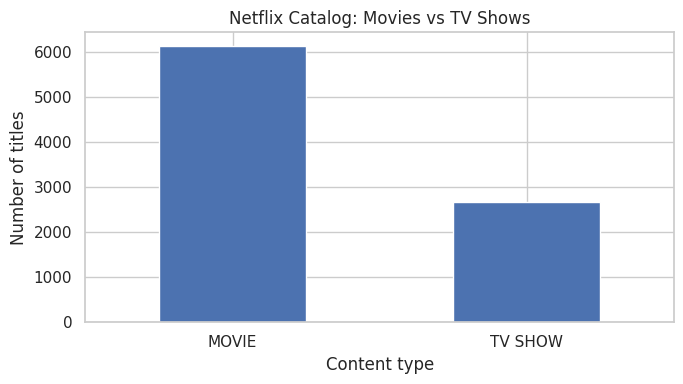

In [ ]:
# Content type distribution
type_counts = df["type"].value_counts()
ax = type_counts.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Netflix Catalog: Movies vs TV Shows")
ax.set_xlabel("Content type")
ax.set_ylabel("Number of titles")
plt.tight_layout()
plt.show()


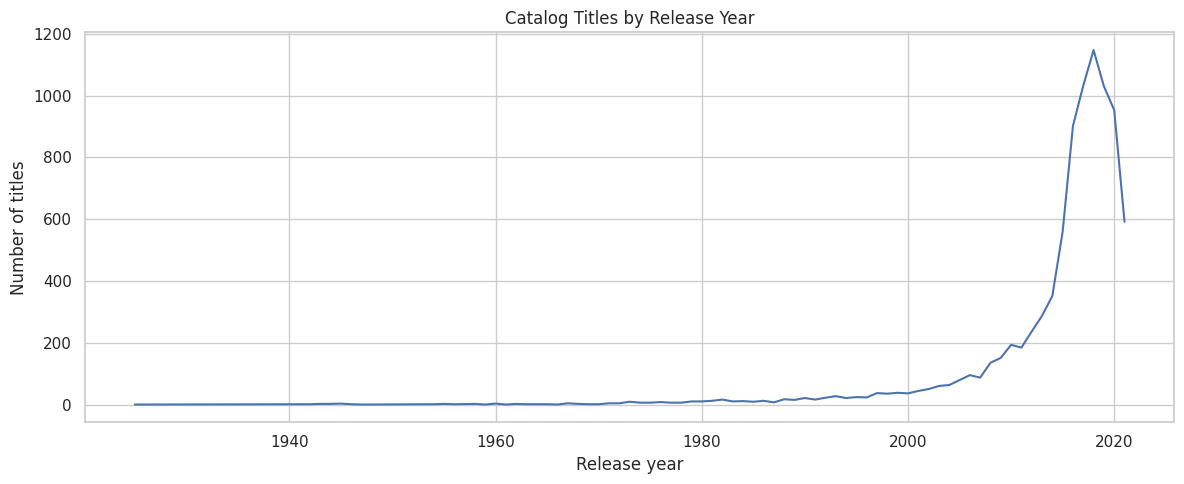

In [ ]:
# Titles by release year
year_counts = df["release_year"].value_counts().sort_index()
plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Catalog Titles by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()


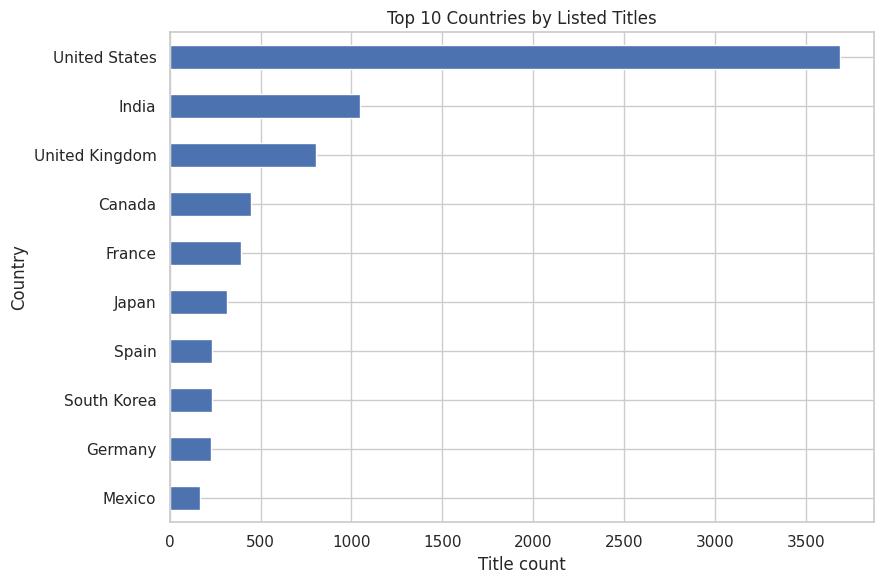

In [ ]:
# Top 10 countries (first listed country; multi-country entries split)
countries = (df["country"].dropna().str.split(",").explode().str.strip())
top_countries = countries.value_counts().head(10).sort_values()
plt.figure(figsize=(9, 6))
top_countries.plot(kind="barh")
plt.title("Top 10 Countries by Listed Titles")
plt.xlabel("Title count")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


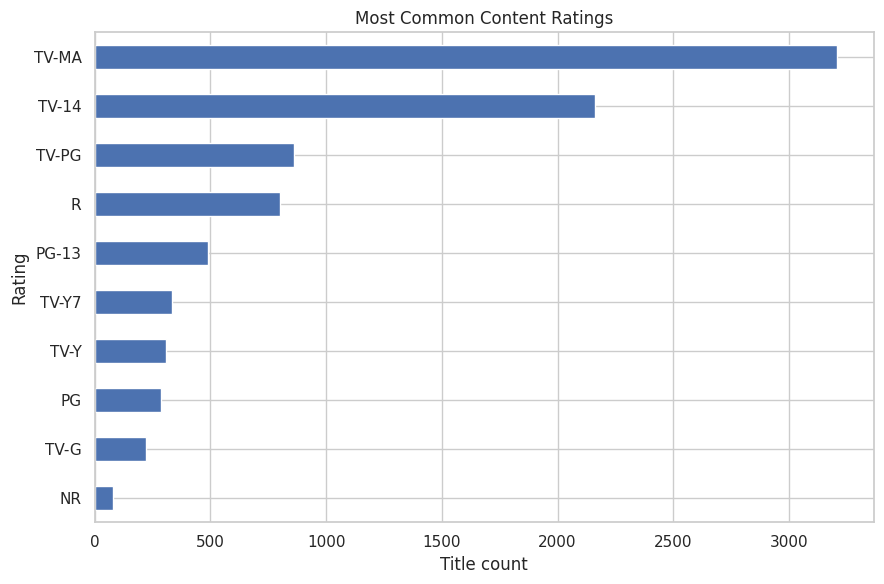

In [ ]:
# Top content ratings
rating_counts = df["rating"].value_counts().head(10).sort_values()
plt.figure(figsize=(9, 6))
rating_counts.plot(kind="barh")
plt.title("Most Common Content Ratings")
plt.xlabel("Title count")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()


## 7. Summary metrics and export cleaned data

In [ ]:
summary = {
    "cleaned_rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows_removed": duplicates_removed,
    "movies": int((df["type"] == "MOVIE").sum()),
    "tv_shows": int((df["type"] == "TV SHOW").sum()),
    "earliest_release_year": int(df["release_year"].min()),
    "latest_release_year": int(df["release_year"].max()),
}
display(pd.Series(summary, name="value").to_frame())
clean_path = DATA_DIR / "netflix_cleaned.csv"
df.to_csv(clean_path, index=False)
print(f"Saved cleaned dataset to: {clean_path}")


,value
cleaned_rows,8807
columns,14
duplicate_rows_removed,0
movies,6131
tv_shows,2676
earliest_release_year,1925
latest_release_year,2021


Saved cleaned dataset to: data/netflix_cleaned.csv
